In [9]:
using LowLevelFEM

In [ ]:
#line_mesh(order=3)
openGeometry("simple-supported-beam.geo")
#openPreProcessor()

In [11]:
mat = Material("body")
U = Field([mat], type=:VectorField, dim=2, fieldName=:u, rhsName=:f)
Φ = Field([mat], type=:ScalarField, dim=2, fieldName=:φ, rhsName=:m, reducedOrder=true);

In [12]:
t = tangentVector(U, "body")
tx, ty, tz = t[1], t[2], t[3]

nx = -ty
ny = tx
nz = 0;

In [13]:
# ------------------------------------------------------------------
# Generalized Timoshenko beam strain
#
# ε = tᵀ ∇u t
# γ = nᵀ ∇u t - φ
# κ = ∇φ ⋅ t
# ------------------------------------------------------------------

Au = [
    tx*tx tx*ty tx*ty ty*ty
    nx*tx nx*ty ny*tx ny*ty
    0 0 0 0]

Aφ = [
    0 0
    0 0
    tx ty]

Gφ = [0; -1; 0;;]

Bu = Au ⋅ Grad(U)

Bφ = Aφ ⋅ Grad(Φ) + Gφ ⋅ Φ;

In [14]:
b = 30
h = 5
E = mat.E
G = mat.μ
Iz = b * h^3 / 12
κ = 4 / 5
A = b * h;

In [15]:
D = [
    E*A 0 0
    0 κ*G*A 0
    0 0 E*Iz]

3×3 Matrix{Float64}:
 3.0e7  0.0        0.0
 0.0    9.23077e6  0.0
 0.0    0.0        6.25e7

In [16]:
B = Bu + Bφ
K = ∫(B' ⋅ D ⋅ B, Γ="body");

In [17]:
supp_uL = BoundaryCondition("left", field=U, ux=0, uy=0)
supp_uR = BoundaryCondition("right", field=U, ux=0, uy=0);

In [18]:
loadf = LoadCondition("body", fy=0)
loadF = LoadCondition("right", fy=0)
loadMid = LoadCondition("mid", fy=-1)
loadM = LoadCondition("right", m=0)

fu = loadVector(U, [loadMid])
fφ = loadVector(Φ, [loadM])

F = SystemVector([fu, fφ]);

In [20]:
u, φ = solveField(K, F, support=[supp_uL, supp_uR]);

In [21]:
showDoFResults(fu, name="force")
showDoFResults(u, name="u", factor=20, visible=true);

In [22]:
n = VectorField([nx, ny, 0]);

In [23]:
u = expandTo3D(u)
φ = nodesToElements(φ)

g = ∇(u)

ε = t ⋅ (g * t)
γ = n ⋅ (g * t) - φ

κb = -∇(φ) ⋅ t

N = E * A * ε
T = κ * G * A * γ
Mh = E * Iz * κb;

In [24]:
N0, plotN = plotOnBeam("body", N, name="N graph", plot=true)
T0, plotT = plotOnBeam("body", T, name="T graph", plot=true)
Mh0, plotMh = plotOnBeam("body", Mh, name="Mh graph", plot=true)

(4, ([0.0, 5.0, 10.0, 10.0, 15.0, 20.0, 20.0, 25.0, 30.0, 30.0  …  170.0, 170.0, 175.0, 180.0, 180.0, 185.0, 190.0, 190.0, 195.0, 200.0], [-2.499999999962495, -2.499999999962654, -2.4999999999629186, -7.499999999887272, -7.499999999887379, -7.499999999887485, -12.499999999809297, -12.499999999809297, -12.499999999809297, -17.49999999972984  …  -17.499999999706443, -12.499999999788121, -12.499999999788148, -12.499999999788228, -7.499999999873508, -7.499999999873667, -7.499999999873508, -2.4999999999578364, -2.4999999999578892, -2.499999999958048]))

In [25]:
using Plots

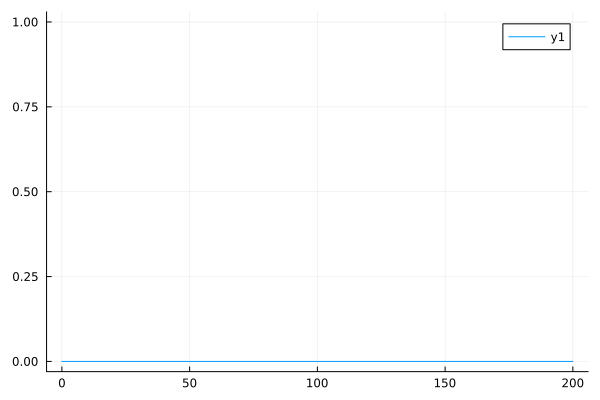

In [26]:
plot(plotN)

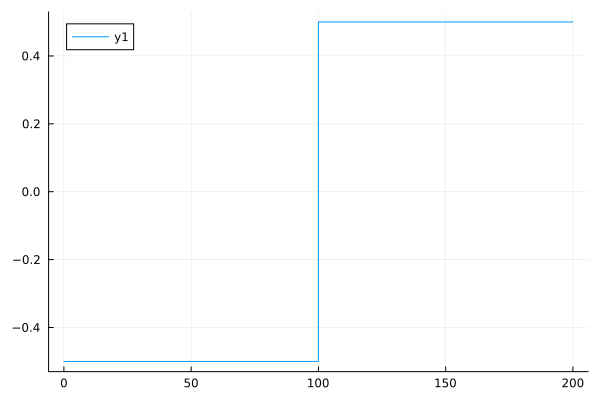

In [27]:
plot(plotT)

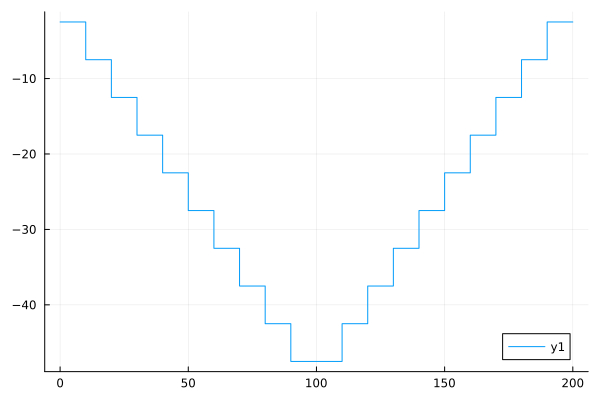

In [28]:
plot(plotMh)

In [29]:
openPostProcessor()